# Classificação de sucesso comercial

Regressão logística para classificar o status registrado na exportação. Locação e venda são analisadas separadamente em `FINALIDADE`.

**Sucesso (1):** Alugado ou Vendido. **Não sucesso (0):** qualquer outro status, inclusive Disponível, Desistência, Outros e vazio.

Essa definição descreve o estado da exportação, não a rapidez nem o resultado futuro do imóvel. Status vazio é tratado como não sucesso por convenção desta análise. Nenhuma data é necessária ou simulada.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report, ConfusionMatrixDisplay,
)
FINALIDADE = "Locação"
SEMENTE = 42
LIMIAR = 0.5
assert FINALIDADE in {"Locação", "Venda"}

## Dados e rótulos

Fonte: `data/raw/imoveis.csv`. Referências repetidas dentro da finalidade são excluídas para evitar duplicação e ambiguidades. A tabela mostra as exclusões antes da divisão.

In [2]:
raiz = Path.cwd()
if not (raiz / "data/raw/imoveis.csv").exists():
    raiz = raiz.parent
base = pd.read_csv(raiz / "data/raw/imoveis.csv", sep=None, engine="python", encoding="cp1252", dtype=str)
for coluna in ["Referência", "Finalidade", "Disponibilidade"]:
    base[coluna] = base[coluna].str.strip().replace("", np.nan)
mercado = base.loc[base.Finalidade.eq(FINALIDADE)].copy()
STATUS_SUCESSO = ["Alugado", "Vendido"]
chave_valida = mercado["Referência"].notna()
repetidos = mercado["Referência"].duplicated(keep=False) & chave_valida
dados = mercado.loc[chave_valida & ~repetidos].copy()
dados["sucesso"] = dados.Disponibilidade.isin(STATUS_SUCESSO).astype(int)
display(mercado.Disponibilidade.value_counts(dropna=False).rename("registros"))
display(pd.Series({
    "Registros da finalidade": len(mercado),
    "Sem referência": int((~chave_valida).sum()),
    "Referências repetidas (linhas)": int(repetidos.sum()),
    "Status vazios incluídos como não sucesso": int(dados.Disponibilidade.isna().sum()),
    "Registros elegíveis": len(dados),
}, name="auditoria"))

display(dados.sucesso.value_counts().rename(index={0: "Não sucesso", 1: "Sucesso"}))
assert dados["Referência"].is_unique
assert dados.sucesso.value_counts().min() >= 8

Disponibilidade
Alugado        86
NaN            40
Desistência    35
Outros         28
Disponível     16
Vendido        11
Name: registros, dtype: int64

Registros da finalidade                     216
Sem referência                                0
Referências repetidas (linhas)                2
Status vazios incluídos como não sucesso     40
Registros elegíveis                         214
Name: auditoria, dtype: int64

sucesso
Não sucesso    118
Sucesso         96
Name: count, dtype: int64

## Entradas

Preço, dormitórios, banheiros, vagas, tipo e bairro. Status, datas, exibição do anúncio e contatos acumulados não são entradas. Isso evita sinais que revelam diretamente o desfecho ou podem ter sido acumulados depois dele. Ausência de uma característica numérica não é interpretada como zero.

In [3]:
dados = dados.rename(columns={"Referência": "referencia_id", "Tipo": "tipo", "Bairro": "bairro"})
preco = dados.Valor.str.replace("R$", "", regex=False).str.replace(".", "", regex=False).str.replace(",", ".", regex=False).str.strip()
dados["valor_anuncio"] = pd.to_numeric(preco, errors="coerce")
for coluna, padrao in {
    "dormitorios": r"(\d+)\s+dormitório",
    "banheiros": r"(\d+)\s+banheiro",
    "garagens": r"(\d+)\s+garage",
}.items():
    dados[coluna] = pd.to_numeric(dados["Características"].str.extract(padrao, expand=False), errors="coerce")
numericas = ["valor_anuncio", "dormitorios", "banheiros", "garagens"]
categoricas = ["tipo", "bairro"]
features = numericas + categoricas
for coluna in categoricas:
    dados[coluna] = dados[coluna].fillna("Não informado").str.strip().replace("", "Não informado")
display(dados[features].isna().sum().rename("ausentes"))

valor_anuncio     0
dormitorios      31
banheiros        21
garagens         35
tipo              0
bairro            0
Name: ausentes, dtype: int64

## Treino e teste

25% dos imóveis ficam no teste, com proporções das classes preservadas e semente fixa. O mesmo imóvel não aparece nos dois conjuntos. O teste não é utilizado para escolher parâmetros ou o limiar de classificação.

In [4]:
treino, teste = train_test_split(dados, test_size=0.25, stratify=dados.sucesso, random_state=SEMENTE)
assert set(treino.referencia_id).isdisjoint(teste.referencia_id)
X_treino, y_treino = treino[features], treino.sucesso
X_teste, y_teste = teste[features], teste.sucesso
if X_treino[numericas].isna().all().any():
    raise ValueError("Uma entrada numérica está inteiramente ausente no treino.")
display(pd.DataFrame({"treino": y_treino.value_counts(), "teste": y_teste.value_counts()}).rename(index={0: "Não sucesso", 1: "Sucesso"}))

,treino,teste
sucesso,,
Não sucesso,88,30
Sucesso,72,24


## Treinamento

O pipeline preenche ausências, padroniza os números e codifica categorias. A regressão logística recebe pesos balanceados entre classes. A validação cruzada em três partes usa somente o treino e refaz a preparação em cada parte.

In [5]:
preparacao = ColumnTransformer([
    ("numericas", Pipeline([
        ("ausencias", SimpleImputer(strategy="median")),
        ("escala", StandardScaler()),
    ]), numericas),
    ("categoricas", OneHotEncoder(handle_unknown="ignore", min_frequency=3), categoricas),
])
modelo = Pipeline([
    ("preparacao", preparacao),
    ("classificador", LogisticRegression(class_weight="balanced", C=1.0, max_iter=2000, random_state=SEMENTE)),
])
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMENTE)
validacao = cross_validate(modelo, X_treino, y_treino, cv=cv,
    scoring={"F1": "f1", "ROC_AUC": "roc_auc", "acuracia_balanceada": "balanced_accuracy"}, error_score="raise")
display(pd.DataFrame([
    {"metrica": nome, "media_validacao": validacao[f"test_{nome}"].mean(),
     "desvio_validacao": validacao[f"test_{nome}"].std()}
    for nome in ["F1", "ROC_AUC", "acuracia_balanceada"]
]))
modelo.fit(X_treino, y_treino)
referencia = DummyClassifier(strategy="prior")
referencia.fit(X_treino, y_treino)

,metrica,media_validacao,desvio_validacao
0,F1,0.438117,0.048011
1,ROC_AUC,0.494205,0.054132
2,acuracia_balanceada,0.483525,0.042130


,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'prior'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](2,)","[0.55,0.45]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](6,)","['valor_anuncio','dormitorios','banheiros','garagens','tipo','bairro']"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,6
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


## Avaliação

Precisão: entre os previstos como sucesso, quantos têm status Alugado ou Vendido. Recall: entre os sucessos registrados, quantos foram identificados. F1 combina precisão e recall. A acurácia balanceada considera as duas classes; ROC-AUC avalia a ordenação dos escores. A referência prevê a classe mais frequente no treino.

,modelo,acuracia,acuracia_balanceada,precisao,recall,F1,ROC_AUC
0,Classe mais frequente,0.556,0.500,0.0,0.000,0.000,0.500
1,Regressão logística,0.556,0.546,0.5,0.458,0.478,0.607


              precision    recall  f1-score   support

 Não sucesso       0.59      0.63      0.61        30
     Sucesso       0.50      0.46      0.48        24

    accuracy                           0.56        54
   macro avg       0.55      0.55      0.55        54
weighted avg       0.55      0.56      0.55        54



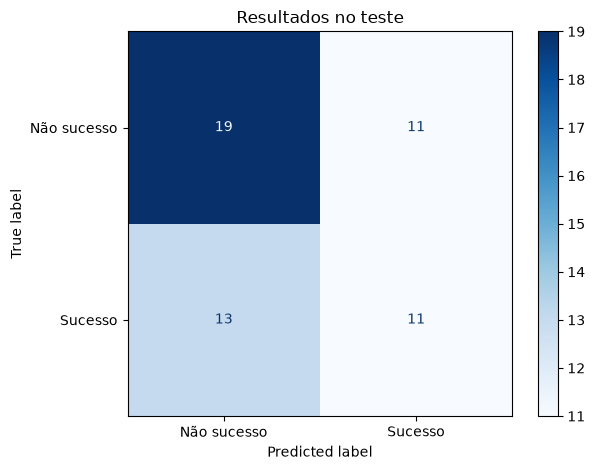

In [6]:
escores = modelo.predict_proba(X_teste)[:, 1]
previsoes = (escores >= LIMIAR).astype(int)
linhas = []
for nome, pred, score in [
    ("Classe mais frequente", referencia.predict(X_teste), referencia.predict_proba(X_teste)[:, 1]),
    ("Regressão logística", previsoes, escores),
]:
    linhas.append({
        "modelo": nome,
        "acuracia": accuracy_score(y_teste, pred),
        "acuracia_balanceada": balanced_accuracy_score(y_teste, pred),
        "precisao": precision_score(y_teste, pred, zero_division=0),
        "recall": recall_score(y_teste, pred, zero_division=0),
        "F1": f1_score(y_teste, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_teste, score),
    })
metricas = pd.DataFrame(linhas)
display(metricas.round(3))
print(classification_report(y_teste, previsoes, labels=[0, 1], target_names=["Não sucesso", "Sucesso"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_teste, previsoes, labels=[0, 1], display_labels=["Não sucesso", "Sucesso"], cmap="Blues")
plt.title("Resultados no teste")
plt.tight_layout()
plt.show()
plt.close()

## Características associadas à classificação

Coeficientes positivos aumentam o escore de sucesso e negativos o reduzem, considerando as outras entradas. São associações deste modelo, não causas nem efeitos isolados. Os números estão padronizados; categorias raras são agrupadas. A tabela descreve o modelo ajustado no treino.

In [7]:
coeficientes = pd.DataFrame({
    "caracteristica": modelo.named_steps["preparacao"].get_feature_names_out(),
    "coeficiente": modelo.named_steps["classificador"].coef_[0],
}).sort_values("coeficiente", ascending=False)
display(coeficientes.head(8))
display(coeficientes.tail(8).sort_values("coeficiente"))

,caracteristica,coeficiente
21,categoricas__bairro_Vila Augusta,0.986624
5,categoricas__tipo_Barracão,0.937992
19,categoricas__bairro_Jardim Vera Cruz,0.839828
13,categoricas__tipo_infrequent_sklearn,0.492574
11,categoricas__tipo_Sala Comercial,0.312221
20,categoricas__bairro_Parque Campolim,0.251718
27,categoricas__bairro_infrequent_sklearn,0.251248
24,categoricas__bairro_Vila Santana,0.218772


,caracteristica,coeficiente
8,categoricas__tipo_Casa em Condomínio,-0.859381
22,categoricas__bairro_Vila Hortência,-0.462596
0,numericas__valor_anuncio,-0.410884
23,categoricas__bairro_Vila Jardini,-0.362534
25,categoricas__bairro_Vossoroca,-0.344043
15,categoricas__bairro_Jardim Emília,-0.319167
7,categoricas__tipo_Casa Comercial,-0.313633
14,categoricas__bairro_Centro,-0.305532


## Conferência das previsões

Os scores abaixo são do teste e seguem a definição de sucesso pelo status da exportação. Não são probabilidades calibradas de fechamento futuro nem medidas de rapidez. A coluna de status permite conferir a origem de cada classe.

In [8]:
resultados = teste[["referencia_id", "tipo", "bairro", "valor_anuncio", "Disponibilidade", "sucesso"]].copy()
resultados["escore_sucesso"] = escores
resultados["classe_prevista"] = previsoes
resultados["acertou"] = resultados.sucesso.eq(resultados.classe_prevista)
display(resultados.sort_values(["acertou", "escore_sucesso"], ascending=[True, False]))

,referencia_id,tipo,bairro,valor_anuncio,Disponibilidade,sucesso,escore_sucesso,classe_prevista,acertou
5,108,Sala Comercial,Vila Santana,1000.0,Desistência,0,0.647713,1,False
71,567,Apartamento Duplex,Parque Reserva Fazenda Imperial,1800.0,Disponível,0,0.610481,1,False
122,494,Casa,Vila Assis,3500.0,NaN,0,0.609727,1,False
149,784,Casa Comercial,Jardim Simus,4500.0,NaN,0,0.603117,1,False
141,ALTERR1,Terreno,Parque Campolim,4000.0,NaN,0,0.566748,1,False
75,777,Apartamento Mobiliado,Bairro da Vossoroca,1950.0,Disponível,0,0.564381,1,False
53,634/L,Casa,Jardim Nova Manchester,1500.0,Desistência,0,0.537507,1,False
172,424/L,Casa Duplex,Jardim Pagliato,7000.0,NaN,0,0.536690,1,False
199,717,Salão Comercial,Jardim Vera Cruz,15000.0,NaN,0,0.535745,1,False
59,102/L,Apartamento,Jardim Faculdade,1690.0,Desistência,0,0.524855,1,False
